# Sesión 5: Inferencia

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Distribución de la media muestral y la proporción muestral

### Media muestral

In [2]:
# Simulemos la población de salarios (Desconocido in Real Life!)
mu = 1400
sigma = 200
salarios = np.random.normal(mu, sigma, 10000)

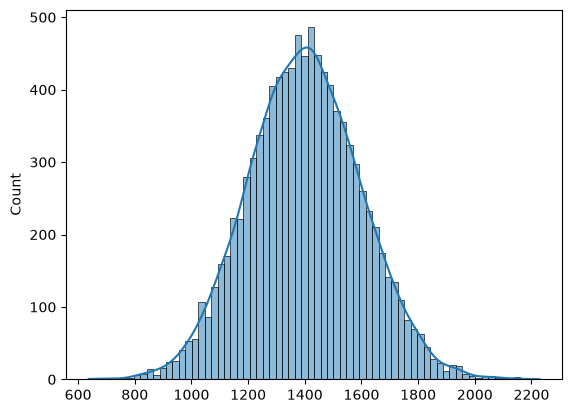

In [3]:
sns.histplot(salarios, bins=70, kde=True)
plt.show()

In [4]:
# Simula las muestras y calcula las medias muestrales
n = 40
sample_means = []
for _ in range(1000):
    sample = np.random.normal(mu, sigma, n)
    sample_mean = np.mean(sample)
    sample_means.append(sample_mean)

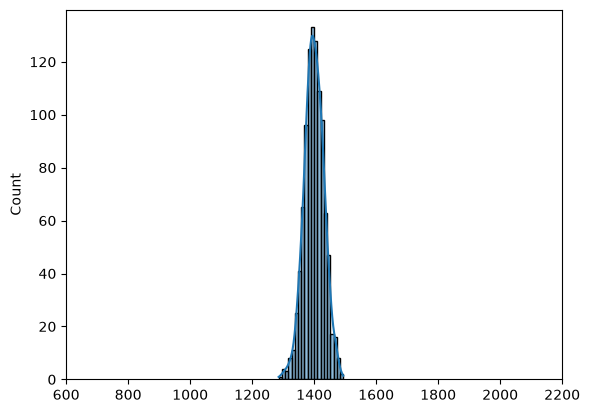

In [5]:
# Plotea histograma de medias muestrales
sns.histplot(sample_means, bins=20, kde=True)
plt.xlim(600, 2200)
plt.show()

### Proporción muestral

In [6]:
# Proporción poblacional (Desconocido in Real Life!)
pi = 0.05

In [7]:
# Ejemplo de muestra
np.random.binomial(1, pi, 1000)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,

In [8]:
# Simula muestras y calcula la proporción muestral
n = 1000
sample_proportions = []
for _ in range(10000):
    count = np.random.binomial(1, pi, n).sum()
    sample_proportion = count/n
    sample_proportions.append(sample_proportion)

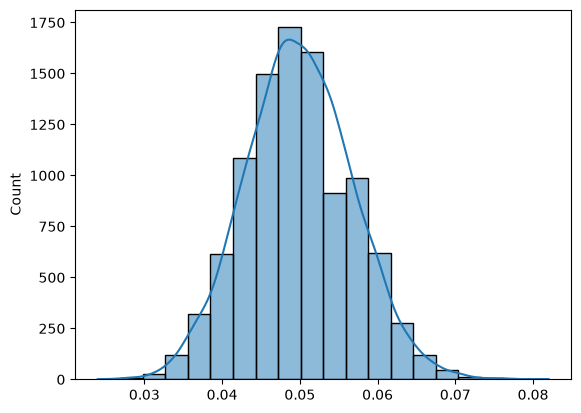

In [9]:
# Plotea histograma de medias muestrales
sns.histplot(sample_proportions, bins=20, kde=True)
plt.show()

## 2. Intervalos de confianza (IC)

https://www.youtube.com/watch?v=tFWsuO9f74o

In [10]:
import scipy.stats as st

#### IC para la media

* Tenemos una muestra de los salarios de $n=40$ adultos trabajadores en un país.
* ¿Cómo calculamos el IC para el salario medio de ese país?

In [11]:
# La siguiente muestra tiene salarios de 40 trabajadores
salarios = np.array([1984.1, 2155.3, 1880.1, 1777.6, 1881.1, 1947.6, 1742.3, 2040.5,
       2072.6, 1902.9, 2142.5, 2078.6, 2040.7, 2151.5, 2473.3, 1847. ,
       2175. , 1921.7, 1915.7, 1900.7, 1479.2, 2178.9, 2106.8, 1457.3,
       2266.7, 1956.3, 1890.1, 1978. , 1976.9, 1763. , 2226.2, 1873. ,
       1815.7, 1441.7, 2027.8, 1766.9, 2074.8, 1996.1, 1878. , 2099. ])

In [12]:
len(salarios)

40

In [13]:
# Para calcular el IC para la media necesitamos
n = 40
media = np.mean(salarios)
s = salarios.std()/np.sqrt(n)

In [14]:
# Calculo IC al 95%
st.t.interval(confidence = .95, df = n-1, loc = media, scale = s)

(np.float64(1890.8343999454933), np.float64(2023.3256000545075))

In [15]:
# Calculo IC al 99%
st.t.interval(confidence = .99, df = n-1, loc = media, scale = s)

(np.float64(1868.3925332394447), np.float64(2045.767466760556))

#### IC para la proporción
* En una muestra de $n=1000$ adultos, un $\hat p =7$% de ellos se identifica como *queer*
* ¿Cuál es el IC para la proporción real $\pi$ de adultos *queer* en toda la población?

In [16]:
p_hat = 0.07
n = 1000
s = np.sqrt(p_hat * (1 - p_hat) / n)

In [17]:
# Calculo IC al 95%
st.norm.interval(confidence = 0.95, loc=p_hat, scale=s)

(np.float64(0.05418611467010123), np.float64(0.08581388532989878))

In [18]:
# Calculo IC al 99%
st.norm.interval(confidence = 0.99, loc=p_hat, scale=s)

(np.float64(0.04921703176332888), np.float64(0.09078296823667113))

In [19]:
(0.04921703176332888 + 0.09078296823667113)/2

0.07

### 🧩 Ejercicio 1

Un analista estima el retorno medio mensual de un activo financiero. Saca una muestra disponible en `retornos.csv`. Preguntas:
- De qué tamaño es la muestra? Cuál es la media muestral?
- IC al 95% para la media? IC al 99%?

In [20]:
import pandas as pd
retornos = pd.read_csv('retornos.csv')

In [21]:
retornos

,Retornos
0,0.000000
1,0.400157
2,1.258848
3,3.122087
4,4.053019
...,...
95,1.868678
96,1.318575
97,2.708873
98,2.023123


In [22]:
n = 100
media = np.mean(retornos)
s = retornos.std()/np.sqrt(n)

In [23]:
# De qué tamaño es la muestra? Cuál es la media muestral?
n, media

(100, np.float64(0.0981342107971759))

In [24]:
# IC al 95% para la media?
st.t.interval(confidence = .95, df = n-1, loc = media, scale = s)

(array([-0.21168089]), array([0.40794931]))

In [25]:
# IC al 99%?
st.t.interval(confidence = .99, df = n-1, loc = media, scale = s)

(array([-0.31195203]), array([0.50822045]))

### 🧩 Ejercicio 2
Un banco analiza 200 préstamos y observa que hay 32 con morosidad.
- Cuál es la proporción muestral?
- Calcula el IC al 95% para la proporción.
- Cómo cambiaría el IC si analizaramos 100 préstamos y observáramos 16 con morosidad?

In [26]:
p_hat = 32/200
n = 200
s = np.sqrt(p_hat * (1 - p_hat) / n)

In [27]:
# Calculo IC al 95%
st.norm.interval(confidence = 0.95, loc=p_hat, scale=s)

(np.float64(0.10919192655191055), np.float64(0.21080807344808944))

In [28]:
# Cómo cambiaría el IC si analizaramos 100 préstamos y observáramos 16 con morosidad?
p_hat = 16/100
n = 100
s = np.sqrt(p_hat * (1 - p_hat) / n)

In [29]:
# Calculo IC al 95%
st.norm.interval(confidence = 0.95, loc=p_hat, scale=s)

(np.float64(0.08814653345166357), np.float64(0.23185346654833644))

## 3. Test de hipótesis

#### T-test para la media

* Tenemos una muestra de los salarios de  $𝑛=40$  adultos trabajadores en un país.
* Unas estadísticas afirman que el salario medio es de 1600€. ¿Es esto compatible con lo que hemos visto en nuestra muestra?

In [30]:
# La siguiente muestra tiene salarios de 40 trabajadores
salarios = np.array([1984.1, 2155.3, 1880.1, 1777.6, 1881.1, 1947.6, 1742.3, 2040.5,
       2072.6, 1902.9, 2142.5, 2078.6, 2040.7, 2151.5, 2473.3, 1847. ,
       2175. , 1921.7, 1915.7, 1900.7, 1479.2, 2178.9, 2106.8, 1457.3,
       2266.7, 1956.3, 1890.1, 1978. , 1976.9, 1763. , 2226.2, 1873. ,
       1815.7, 1441.7, 2027.8, 1766.9, 2074.8, 1996.1, 1878. , 2099. ])

In [31]:
salarios.mean()

np.float64(1957.0800000000004)

In [32]:
from scipy.stats import ttest_1samp

In [33]:
# Test para ver si la media poblacional es mayor que 1600
ttest_1samp(salarios, popmean = 1600)

TtestResult(statistic=np.float64(10.765651589097645), pvalue=np.float64(3.040245844555931e-13), df=np.int64(39))

**Insights**
* El test es conclusivo.
* 💡 Si las estadísticas afirman que el salario medio está en 2000€ ¿sería esto refutable?

In [34]:
ttest_1samp(salarios, popmean = 2000)

TtestResult(statistic=np.float64(-1.2940006894927365), pvalue=np.float64(0.2032759194203285), df=np.int64(39))

### z-test para la proporción

* En una muestra de  $𝑛=1000$  adultos, un  $\hat p=7$ % de ellos se identifica como queer.
* Unas estadísticas afirman que sólo el $5$% de la población adulta es queer. ¿Nos lo creemos?

$$H_0 : \pi = 0.05$$
$$H_1 : \pi > 0.05$$


In [35]:
from statsmodels.stats.proportion import proportions_ztest

In [36]:
zstat, pvalue = proportions_ztest(70, 1000, value=0.05)
pvalue

np.float64(0.01318293900551695)

**Insights**
* El test es conclusivo.
* 💡 ¿Qué pasaría si nuestra muestra fuese de 100 adultos, 7 de los cuales fueran queer?

In [37]:
zstat, pvalue = proportions_ztest(7, 100, value=0.05)
pvalue

np.float64(0.4331212055778665)

### 🧩 Ejercicio 1
Un ministro de sanidad optimista anuncia que de media, la población de su país tiene un colesterol de 200 mg/dL. Sacas la siguiente muestra:

`valores_colesterol = np.array([192.4, 197.1, 194.8, 208.6, 199.2, 209.5, 211.1, 198.4, 204. , 209.6, 218.4, 211.7, 198.3, 204.4, 207.6])`

* Provienen estos datos de una variable aleatoria normal con  $\mu = 200$ mg/dL?

In [38]:
valores_colesterol = np.array([192.4, 197.1, 194.8, 208.6, 199.2, 209.5, 211.1, 198.4, 204. , 209.6, 218.4, 211.7, 198.3, 204.4, 207.6])

In [39]:
ttest_1samp(valores_colesterol, popmean = 200, alternative="greater")

TtestResult(statistic=np.float64(2.2740107019345954), pvalue=np.float64(0.019617112402957965), df=np.int64(14))

### 🧩 Ejercicio 2
Un e-commerce realiza un estudio y ve que de 500 usuarios que clickan en un producto 15 acaban comprando.
* ¿Cuál es la conversión para esa muestra?
* El competidor se sabe que tiene una conversión del 2%. ¿Se puede afirmar que nuestro e-commerce tiene una conversiónn más elevado que el del competidor? ¿Y si fuesen 30 de 1000?

In [40]:
zstat, pvalue = proportions_ztest(15, 500, value=0.02, alternative='larger')
pvalue

np.float64(0.09496161307581885)

In [41]:
zstat, pvalue = proportions_ztest(30, 1000, value=0.02, alternative='larger')
pvalue

np.float64(0.03188675213519529)